### Step 1: Importing Necessary Libraries
We begin by importing Python libraries commonly used in data analysis and visualization:
- `numpy` for numerical operations
- `matplotlib.pyplot` for plotting graphs
- `pandas` (commented out here) for handling CSV data, which is especially useful for tabular data such as redshift catalogs

> Tip: If you haven’t used `pandas` before, it’s worth learning as it offers powerful tools to manipulate and analyze structured datasets.


For reading big csv files, one can use numpy as well as something called "pandas". We suggest to read pandas for CSV file reading and use that

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from astropy.constants import G, c
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u
import warnings
from astropy.coordinates import SkyCoord
import plotly.graph_objects as go
import json


Before we begin calculations, we define key physical constants used throughout:

- $ H_0 $: Hubble constant, describes the expansion rate of the Universe.
- $c$ : Speed of light.
-  $G$: Gravitational constant.
- $q_0$ : Deceleration parameter, used for approximate co-moving distance calculations.

We will use **`astropy.constants`** to ensure unit consistency and precision.

In [2]:
# Constants:

H_0 = cosmo.H0                            # Hubble constant in SI

c = c                # Speed of light in m/s
G_pc = G.to((u.pc * (u.m / u.s) **2) / u.kg)           # Gravitational constant in pc kg^-1 (m/s)^2

q0= -0.534                              # Deceleration parameter (assumed from Planck fit KEEP it as it is)
print(f'{H_0},\n {c},\n {G_pc},\n {q0}')


67.66 km / (Mpc s),
 299792458.0 m / s,
 2.1629933211538522e-27 m2 pc / (kg s2),
 -0.534


Read the csv data into the python using the method below

In [25]:
df = pd.read_csv("output.csv", dtype = {'objid' : str}) # Download the data as instructed in the pdf
df.head()

#df.dtypes

#df['objid'] = df['objid'].apply(lambda x: f"{int(x):d}")
#df.to_csv('output.csv', index=False)


,objid,ra,dec,photoz,photozerr,specz,speczerr,proj_sep,umag,umagerr,gmag,gmagerr,rmag,rmagerr,obj_type
0,1237671768542478711,257.82458,64.133257,0.079193,0.022867,0.082447,0.000017,8.347733,18.96488,0.043377,17.49815,0.005672,16.75003,0.004708,3.0
1,1237671768542478711,257.82458,64.133257,0.079193,0.022867,0.082466,0.000014,8.347733,18.96488,0.043377,17.49815,0.005672,16.75003,0.004708,3.0
2,1237671768542478713,257.83332,64.126043,0.091507,0.014511,0.081218,0.000021,8.011259,20.22848,0.072019,18.38334,0.007763,17.46793,0.005828,3.0
3,1237671768542544090,257.85137,64.173247,0.081102,0.009898,0.079561,0.000022,8.739276,19.21829,0.050135,17.18970,0.004936,16.22043,0.003769,3.0
4,1237671768542544090,257.85137,64.173247,0.081102,0.009898,0.079568,0.000019,8.739276,19.21829,0.050135,17.18970,0.004936,16.22043,0.003769,3.0


### 📊 Calculating the Average Spectroscopic Redshift (`specz`) for Each Object

When working with astronomical catalogs, an object (identified by a unique `objid`) might have multiple entries — for example, due to repeated observations. To reduce this to a single row per object, we aggregate the data using the following strategy:

```python
averaged_df = df.groupby('objid').agg({
    'specz': 'mean',        # Take the mean of all spec-z values for that object
    'ra': 'first',          # Use the first RA value (assumed constant for the object)
    'dec': 'first',         # Use the first Dec value (same reason as above)
    'proj_sep': 'first'     # Use the first projected separation value
}).reset_index()


In [4]:
#df['objid'] = df['objid'].astype(str)
#df.to_csv('out_put.csv', index=False)
#df.describe()['specz']

#unique_ids = df['objid'].unique()
#print(unique_ids)

In [5]:
# Calculating the average specz for each id:

averaged_df = df.groupby('objid').agg({'specz': 'mean','ra': 'first','dec': 'first','proj_sep': 'first', 'umag': 'mean','gmag': 'mean','rmag': 'mean'}).reset_index()
averaged_df.describe()['specz']
#print(averaged_df['specz'].count())
#print(averaged_df['specz'])

count    91.000000
mean      0.080850
std       0.008614
min       0.069976
25%       0.077464
50%       0.080923
75%       0.082798
max       0.150886
Name: specz, dtype: float64

To create a cut in the redshift so that a cluster can be identified. We must use some logic. Most astronomers prefer anything beyond 3*sigma away from the mean to be not part of the same group. 

Find the mean, standard deviation and limits of the redshift from the data

In [26]:
mean = df['specz'].mean()
std = df['specz'].std()
z_lower = mean - (3 * std)
z_upper = mean + (3 * std)
print(f'Mean: {mean}\nStandard Deviation: {std}\nLower Limit: {z_upper}\nUpper Limit: {z_lower}')


Mean: 0.08104694625899282
Standard Deviation: 0.009497709534680291
Lower Limit: 0.10954007486303369
Upper Limit: 0.05255381765495195


You can also use boxplot to visualize the overall values of redshift 

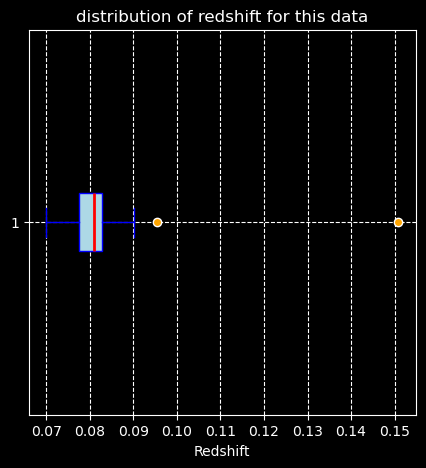

In [7]:
# Plot the dsitribution of redshift as histogram and a boxplot 
plt.figure(figsize = (5,5))
plt.title("distribution of redshift for this data")
plt.boxplot(averaged_df['specz'].dropna(), vert=False, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red', linewidth=2),
            whiskerprops=dict(color='blue'),
            capprops=dict(color='blue'),
            flierprops=dict(marker='o', markerfacecolor='orange', markersize=6, linestyle='none'))
#plt.hist(averaged_df['specz'], color='skyblue', edgecolor='black', alpha=0.7)
plt.xlabel('Redshift')
plt.grid(True, linestyle = '--')
plt.show()

This boxplot helps visualize the distribution and identify redshift outliers in your dataset, which is essential for confirming cluster membership and ensuring accurate dynamical mass estimation.

But the best plot would be a histogram to see where most of the objects downloaded lie in terms of redshift value

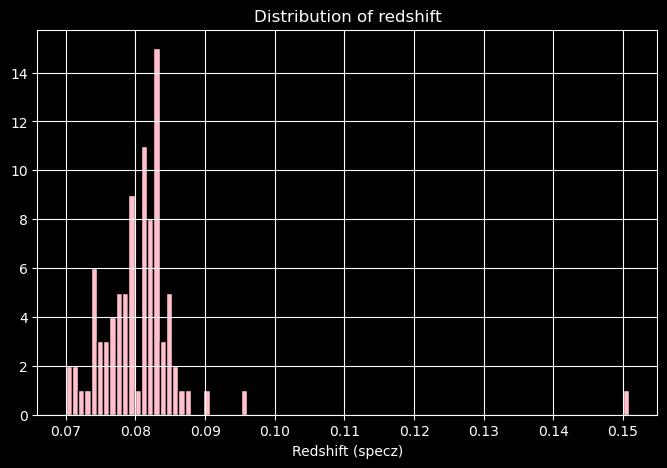

In [8]:
plt.figure(figsize = (8,5))
plt.hist(averaged_df['specz'],bins=90, color = 'pink', edgecolor = 'black', alpha = 1)
plt.title('Distribution of redshift')
plt.xlabel('Redshift (specz)')
plt.grid()
plt.show()

Filter your data based on the 3-sigma limit of redshift. You should remove all data points which are 3-sigma away from mean of redshift

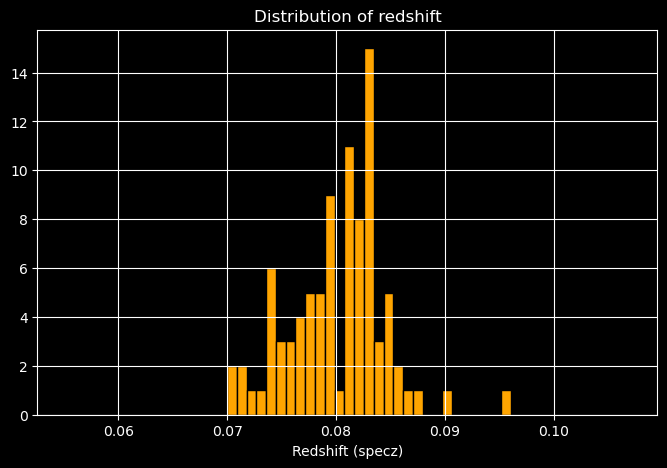

In [9]:
# Filtering the data based on specz values, used 3 sigma deviation from mean as upper limit.
plt.figure(figsize = (8,5))
plt.hist(averaged_df['specz'],bins=90, color = 'orange', edgecolor = 'black', alpha = 1)
plt.title('Distribution of redshift')
plt.xlabel('Redshift (specz)')
plt.xlim(z_lower, z_upper)
plt.grid()
plt.show()

Use the relation between redshift and velocity to add a column named velocity in the data. This would tell the expansion velocity at that redshift 

In [10]:
z_filtered_df = averaged_df[(averaged_df['specz'] >= z_lower) & (averaged_df['specz'] <= z_upper)].copy()
z_filtered_df['velocity'] = np.where(
    z_filtered_df['specz'] >= 0.1,
    c * ((1 + z_filtered_df['specz'])**2 - 1) / ((1 + z_filtered_df['specz'])**2 + 1),  # relativistic
    c * z_filtered_df['specz']  # linear
)
print(f"Number of cluster galaxies selected: {len(z_filtered_df)}")
print(z_filtered_df.head())

#print(z_filtered_df['velocity'])

Number of cluster galaxies selected: 90
                 objid     specz         ra        dec  proj_sep      umag  \
0  1237671768542478711  0.082457  257.82458  64.133257  8.347733  18.96488   
1  1237671768542478713  0.081218  257.83332  64.126043  8.011259  20.22848   
2  1237671768542544090  0.079564  257.85137  64.173247  8.739276  19.21829   
3  1237671768542544107  0.080842  257.89303  64.141138  6.839642  20.34384   
4  1237671768542544127  0.084575  257.91585  64.107290  5.666108  19.52582   

       gmag      rmag      velocity  
0  17.49815  16.75003  2.471993e+07  
1  18.38334  17.46793  2.434867e+07  
2  17.18970  16.22043  2.385281e+07  
3  18.49229  17.55583  2.423576e+07  
4  17.73949  16.85169  2.535507e+07  


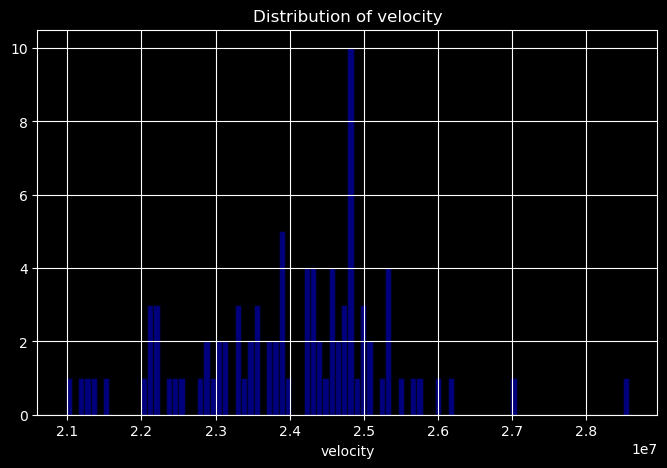

In [11]:
#plot the velocity column created as hist
plt.figure(figsize = (8,5))
plt.hist(z_filtered_df['velocity'],bins=90, color = 'blue', edgecolor = 'black', alpha = 0.5)
plt.title('Distribution of velocity')
plt.xlabel('velocity')
#v_lower = (c * z_lower).value
#v_upper = (c * z_upper).value
#plt.xlim(v_lower, v_upper)
plt.grid()
plt.show()

In [12]:
#plt.figure(figsize = (8,5))
#plt.hist(averaged_df['velocity'],bins=90, color = 'blue', edgecolor = 'black', alpha = 1)
#plt.title('Distribution of velocity')
#plt.xlabel('velocity')
#v_lower = (c * z_lower).value
#v_upper = (c * z_upper).value
#plt.xlim(v_lower, v_upper)
#plt.grid()
#plt.show()

use the dispersion equation to find something called velocity dispersion. You can even refer to wikipedia to know about the term [wiki link here](https://en.wikipedia.org/wiki/Velocity_dispersion#:~:text=In%20astronomy%2C%20the%20velocity%20dispersion,%2C%20galaxy%20cluster%2C%20or%20supercluster.)

It is the velocity dispersion value which tells us, some galaxies might be part of even larger groups!!

### Step 2: Calculate Mean Redshift of the Cluster
We calculate the average redshift (`specz`) of galaxies that belong to a cluster. This gives us an estimate of the cluster's systemic redshift.

`cluster_redshift = filtered_df['specz'].mean()`


The velocity dispersion \( v \) of galaxies relative to the cluster mean redshift is computed using the relativistic Doppler formula:

$$
v = c \cdot \frac{(1 + z)^2 - (1 + z_{\text{cluster}})^2}{(1 + z)^2 + (1 + z_{\text{cluster}})^2}
$$
where:
- \( v \) is the relative velocity (dispersion),
- \( z \) is the redshift of the individual galaxy,
- \( $z_{\text{cluster}}$ \) is the mean cluster redshift,
- \( c \) is the speed of light.


In [13]:
cluster_redshift = z_filtered_df['specz'].mean()
#print(cluster_redshift)
relative_velocity = ((((1 + z_filtered_df['specz']) ** 2) - ((1 + cluster_redshift) ** 2)) / 
                       (((1 + z_filtered_df['specz']) ** 2) + ((1 + cluster_redshift) ** 2))) * c
#print(relative_velocity)


Pro tip: Check what the describe function of pandas does. Does it help to get quick look stats for your column of dispersion??

In [14]:
summary = z_filtered_df['velocity'].describe()
dispersion = (summary['std'] * u.m / u.s).to(u.km / u.s)
#print(dispersion)
print(f'Velocity dispersion: {dispersion : .2f} ')

Velocity dispersion:  1317.22 km / s 


In [15]:
print(f"The value of the cluster redshift = {cluster_redshift:.5f}")
print(f"The characteristic value of velocity dispersion of the cluster along the line of sight = {dispersion:.4f}")

The value of the cluster redshift = 0.08007
The characteristic value of velocity dispersion of the cluster along the line of sight = 1317.2174 km / s


### Step 4: Visualizing Angular Separation of Galaxies
We plot a histogram of the projected (angular) separation of galaxies from the cluster center. This helps us understand the spatial distribution of galaxies within the cluster field.

- The x-axis represents the angular separation (in arcminutes or degrees, depending on units).
- The y-axis shows the number of galaxies at each separation bin.



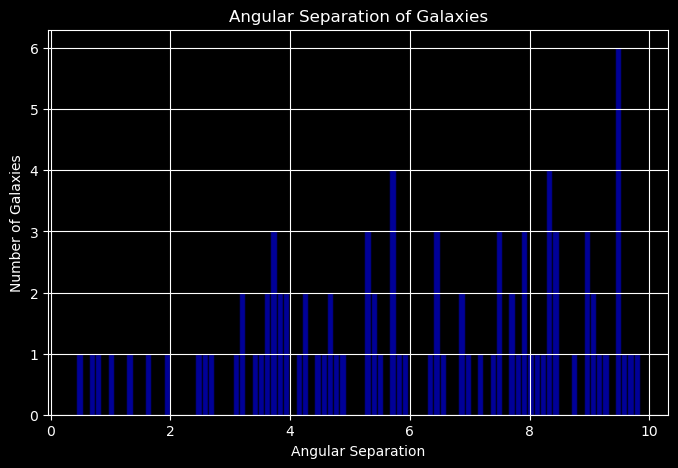

In [16]:
#Plot histogram for proj sep column
plt.figure(figsize = (8,5))
plt.hist(averaged_df['proj_sep'], bins = 90, color = 'blue', edgecolor = 'black', alpha = 0.6)
plt.title('Angular Separation of Galaxies', fontsize = 12)
plt.xlabel('Angular Separation')
plt.ylabel('Number of Galaxies')
plt.grid()
plt.show()

### Determining size and mass of the cluster:

### Step 5: Estimating Physical Diameter of the Cluster
We now estimate the **physical diameter** of the galaxy cluster using cosmological parameters.

- `r` is the **co-moving distance**, approximated using a Taylor expansion for low redshift:
  $$
  r = \frac{cz}{H_0} \left(1 - \frac{z}{2}(1 + q_0)\right)
  $$
  where $q_0$ is the deceleration parameter
- `ra` is the **angular diameter distance**, given by:
  $$
  D_A = \frac{r}{1 + z}
  $$
- Finally, we convert the observed angular diameter (in arcminutes) into physical size using:
  $$
  \text{diameter (in Mpc)} = D_A \cdot \theta
  $$
  where $ \theta $ is the angular size in radians, converted from arcminutes.

> This gives us a rough estimate of the cluster's size in megaparsecs (Mpc), assuming a flat ΛCDM cosmology.


In [17]:
r = (((c * cluster_redshift) * (1 - (cluster_redshift * (1 + q0)) / 2)) / H_0).to(u.Mpc)
ra = r / (1 + cluster_redshift)
θ_arcmin = ((averaged_df['proj_sep']).mean()) * u.arcmin 
print(f'{r}\n{ra}\n{θ_arcmin}')
θ = θ_arcmin.to(u.rad).value
#print(θ)
diameter = ra * θ
#print(diameter, 'rad')
diameter_Mpc = diameter.to(u.Mpc)    #in Mpc
print(diameter_Mpc)

348.1696374343458 Mpc
322.35777078547073 Mpc
6.061323666736263 arcmin
0.5683707717576245 Mpc


### Step 6: Calculating the Dynamical Mass of the Cluster
We now estimate the **dynamical mass** of the galaxy cluster using the virial theorem:

$$
M_{\text{dyn}} = \frac{3 \sigma^2 R}{G}
$$

Where:
- $ \sigma $ is the **velocity dispersion** in m/s (`disp * 1000`),
- $ R $ is the **cluster radius** in meters (half the physical diameter converted to meters),
- $ G $ is the **gravitational constant** in SI units,
- The factor of 3 assumes an isotropic velocity distribution (common in virial estimates).

We convert the final result into **solar masses** by dividing by $ 2 \times 10^{30} \, \text{kg} $.

> This mass estimate assumes the cluster is in dynamical equilibrium and bound by gravity.


In [18]:
### Calculating the dynamical mass in solar masses:
M_dyn = 3 * (((dispersion * 1000)**2) * (diameter * 0.5 * 10 ** 6 * 3 * 10 ** 16) / (G * 2 * 10 ** 30)).value

print(f"Dynamical Mass of the cluster is {M_dyn:.2e} solar mass")

Dynamical Mass of the cluster is 3.32e+14 solar mass


CALCULATING LUMINOUS MASS FOR THE GALAXY CLUSTER

In [19]:
z_filtered_df['lum_dist_pc'] = cosmo.luminosity_distance(z_filtered_df['specz']).to(u.pc).value


We use the r-band for calculating luminous mass because it traces older, mass-dominant stellar populations, is less affected by dust, and offers lower mass-to-light (M/L) ratio variance across galaxy types compared to bluer bands like u or g. This makes r-band light a more stable and reliable proxy for stellar mass.


In [20]:
#Define absolute magnitude of the Sun in SDSS bands
M_sun = {'u': 6.39, 'g': 5.12, 'r': 4.67}  
#Calculate absolute magnitude and luminosity
for band in ['u', 'g', 'r']:
    m_col = f'{band}mag'
    M_col = f'absMag_{band}'
    L_col = f'lum_{band}_Lsun'

    z_filtered_df[M_col] = z_filtered_df[m_col] - 5 * np.log10(z_filtered_df['lum_dist_pc'] / 10)
    z_filtered_df[L_col] = 10 ** (-0.4 * (z_filtered_df[M_col] - M_sun[band]))

# Total r-band luminosity
total_L_r = z_filtered_df['lum_r_Lsun'].sum()
# Assuming M/L ratio (mass-to-light)  clusters in r-band
#mass_to_light_ratio_r = M_dyn / total_L_r  # solar masses per solar luminosity (typical for clusters)
z_filtered_df['g_r'] = z_filtered_df['gmag'] - z_filtered_df['rmag']
z_filtered_df['log_M_L_r'] = -0.306 + 1.097 * z_filtered_df['g_r']
z_filtered_df['M_L_r'] = 10 ** z_filtered_df['log_M_L_r']
mass_to_light_ratio_r = z_filtered_df['M_L_r'].mean()

# Luminous mass estimate in solar masses
luminous_mass_r = total_L_r * mass_to_light_ratio_r
print(f"\nEstimated total luminous mass of the cluster (r-band): {luminous_mass_r:.2e} M☉")



Estimated total luminous mass of the cluster (r-band): 1.02e+13 M☉


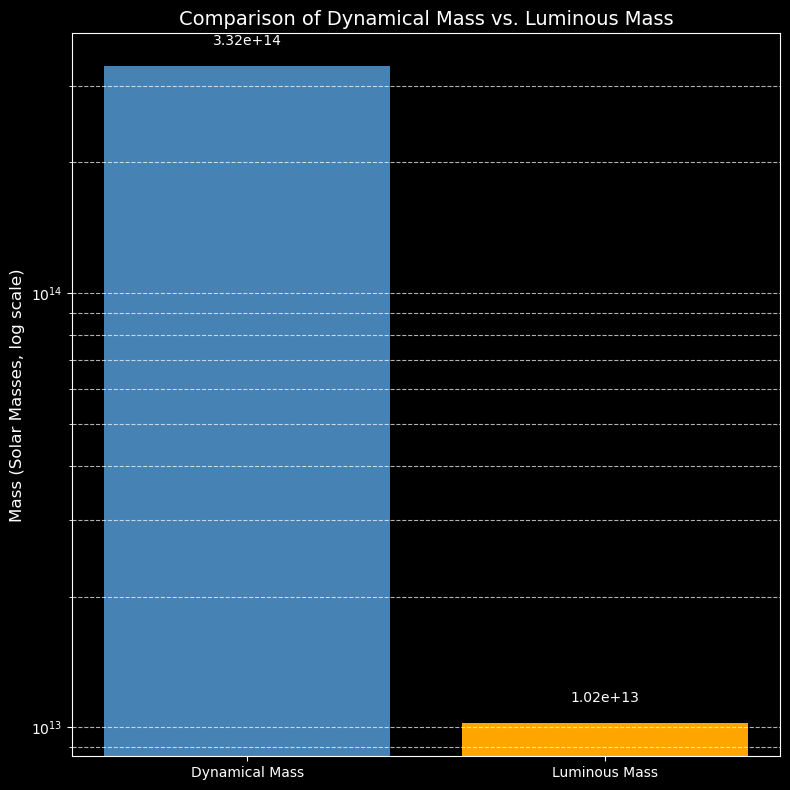

In [21]:
# Data for bar plot
mass_types = ['Dynamical Mass', 'Luminous Mass']
mass_values = [M_dyn, luminous_mass_r]

# Plot
plt.figure(figsize=(8, 8))
bars = plt.bar(mass_types, mass_values, color=['steelblue', 'orange'])

# Add value labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval * 1.1, f'{yval:.2e}', ha='center', va='bottom', fontsize=10)

# Log scale and labels
plt.yscale('log')
plt.ylabel('Mass (Solar Masses, log scale)', fontsize=12)
plt.title('Comparison of Dynamical Mass vs. Luminous Mass', fontsize=14)
plt.grid(axis = 'y', which = 'both', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [22]:
mass_to_light_ratio = M_dyn / luminous_mass_r
print(f'Mass to light ratio = {mass_to_light_ratio}')

Mass to light ratio = 32.5502417308221


The results suggest a discrepancy. The luminous mass calculated using the given data seems too low compared to the dynamical mass, which indicates possible missing light sources or calculation biases. Typical mass-to-light ratios for galaxy clusters are around 100–300, because most of a cluster’s mass is dark matter, not luminous matter.

The dynamical mass of a galaxy cluster includes the total mass (visible + dark) required to account for the observed motion of galaxies, while the luminous mass accounts only for the mass of visible matter like stars and gas. A large difference between them indicates the presence of dark matter, which exerts gravitational influence but does not emit light. This supports the idea that galaxy clusters are dark matter-dominated systems, crucial to understanding structure formation in the universe.

SAVING THE RESULTS IN A JSON FILE

In [23]:
results = {
    "cluster_redshift": float(cluster_redshift),
    "velocity_dispersion": float(dispersion.value),
    "diameter_mpc": float(diameter_Mpc.value),
    "dynamical_mass": float(M_dyn),
    "luminous_mass_r": float(luminous_mass_r),
    "mass-to-light-ratio": float(mass_to_light_ratio)
}

with open("final_results.json", "w") as f:
    json.dump(results, f, indent=4)